# SOL 网格交易收益上界实验

## 背景

网格交易不预测价格，而是收割价格路径的波动。在理想无摩擦（无手续费、无滑点、无最小报价单位）、网格间距 $\delta \to 0$ 时，每单位价格变动对应的交易量固定为 $q$，则收益上界为价格路径的**总变差**：

$$TV=\sum_{t=1}^{T}|p_t-p_{t-1}|, \qquad R_{\text{upper}}=q\cdot TV$$

本 notebook 用 `data/sol_usdt_1h.csv`（2022-01-01 ~ 2025-12-31）做三件事：

- **实验 A**：纯多网格，固定每格交易量 $q=1$，分段给足资金，扫描间距 $\delta$；
- **实验 A2**：对称多空网格（允许做空、FIFO 配对），检验上下两腿都兑现后收益是否更接近上界；
- **实验 B**：固定总资金 $M=100{,}000$，每档均分现金 $M/N$，检验 $\delta\to0$ 时收益是否反而趋于 0。

引擎 `scripts/grid_upper_bound.py` 采用经典低买高卖网格：纯多时纯现金起步、不做空；多空时起始价上下对称挂单、持仓可正可负。

In [1]:
import sys
from pathlib import Path


def _find_root(p):
    for q in [p, *p.parents]:
        if (q / "pyproject.toml").exists():
            return q
    return p


ROOT = _find_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

_cjk = [f.name for f in font_manager.fontManager.ttflist
        if f.name in ("Noto Sans CJK SC", "Noto Sans SC", "Source Han Sans SC",
                      "SimHei", "Microsoft YaHei", "PingFang SC", "WenQuanYi Zen Hei")]
if not _cjk:
    _cjk = [f.name for f in font_manager.fontManager.ttflist
            if ("CJK" in f.name or "Han" in f.name)]
if _cjk:
    plt.rcParams["font.family"] = _cjk[0]

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.unicode_minus"] = False

import scripts.grid_upper_bound as gub

print("repo root:", ROOT)
print("font:", plt.rcParams["font.family"])

repo root: /home/nullwinters/Projects/CryptoGrid
font: ['Noto Sans CJK SC']


In [2]:
DATA = ROOT / "data" / "sol_usdt_1h.csv"
if not DATA.exists():
    raise FileNotFoundError(
        f"{DATA} 不存在，请先运行: "
        "uv run python scripts/fetch_ohlcv.py --symbol SOL/USDT --timeframe 1h"
    )

df = pd.read_csv(DATA, parse_dates=["timestamp"])
df = df[(df["timestamp"] >= "2022-01-01") & (df["timestamp"] <= "2025-12-31 23:00:00")].reset_index(drop=True)

LOW, HIGH = float(df["close"].min()), float(df["close"].max())
TV = float(df["close"].diff().abs().sum())
NET = float(df["close"].iloc[-1] - df["close"].iloc[0])
BH = float(df["close"].iloc[-1] / df["close"].iloc[0] - 1)

# 收盘价路径：把每根 bar 的 open/high/low 压成 close，用线性穿越近似理论中的离散价格路径
close_path = df.copy()
for c in ("open", "high", "low"):
    close_path[c] = close_path["close"]

print(f"样本: {len(df):,} 根 1h bar  ({df.timestamp.min()} ~ {df.timestamp.max()})")
print(f"价格区间: {LOW:.2f} ~ {HIGH:.2f} USDT")
print(f"总变差 TV = {TV:,.2f}")
print(f"net = {NET:,.2f}   (TV+net)/2 = {(TV + NET) / 2:,.2f}")
print(f"Buy&Hold = {BH * 100:.2f}%")

样本: 35,057 根 1h bar  (2022-01-01 00:00:00 ~ 2025-12-31 23:00:00)
价格区间: 8.29 ~ 288.87 USDT
总变差 TV = 24,757.25
net = -47.69   (TV+net)/2 = 12,354.78
Buy&Hold = -27.65%


## 引擎与成交口径

- 每根 bar 先撮合卖单（`high >= price`），再撮合买单（`low <= price`），只做单次触发，不模拟 bar 内路径。
- 理想成交价取网格档位价 $p$，使每次完整往返恰好赚一个价差 $\delta$。若按现有 `DynamicBandGrid` 的 `min/max(open, price)` 成交，会在 OHLC 粒度下把跳空也算作利润，收益可超过 $TV$，不再是有意义的理想上界。
- 利润按**档位配对**结转（纯多时卖单与其来源买单作差；多空时用 long/short 两套 FIFO 队列配对），不按持仓均价结转，避免把浮动盈亏计入网格收益。
- 为对照，分别跑两条价格路径：`OHLC(high/low)` 使用真实高低价，`收盘价路径` 与 $TV$ 定义一致。

In [3]:
SPACINGS = [10, 5, 2, 1, 0.5, 0.2, 0.1, 0.05, 0.01]
CAP_A = {
    10: 10_000, 5: 20_000, 2: 50_000, 1: 100_000, 0.5: 200_000,
    0.2: 500_000, 0.1: 1_000_000, 0.05: 2_000_000, 0.01: 10_000_000,
}


def run_A(data, tag, fill_at_level=True):
    rows = []
    for d in SPACINGS:
        m = gub.run_experiment(
            data, lower=LOW, upper=HIGH, spacing=d, mode="fixed_q",
            initial_cash=CAP_A[d], q_unit=1.0, fill_at_level=fill_at_level,
        )["metrics"]
        m = dict(m)
        m["path"] = tag
        m["profit_over_tv"] = m["realized_profit"] / TV
        rows.append(m)
    return pd.DataFrame(rows)


dfA = pd.concat([run_A(close_path, "收盘价路径"), run_A(df, "OHLC(high/low)")], ignore_index=True)
dfA[["path", "spacing", "n_levels", "buys", "sells", "realized_profit",
     "profit_over_tv", "max_cash_deployed", "capital_exhausted", "final_position"]]

,path,spacing,n_levels,buys,sells,realized_profit,profit_over_tv,max_cash_deployed,capital_exhausted,final_position
0,收盘价路径,10.00,29,118,113,1130.00,0.045643,1.330857e+03,False,5.0
1,收盘价路径,5.00,57,380,370,1850.00,0.074726,2.533428e+03,False,10.0
2,收盘价路径,2.00,141,1678,1654,3308.00,0.133617,6.749713e+03,False,24.0
3,收盘价路径,1.00,282,4601,4553,4553.00,0.183906,1.382714e+04,False,48.0
4,收盘价路径,0.50,562,11527,11431,5715.50,0.230862,2.832100e+04,False,96.0
5,收盘价路径,0.20,1404,34493,34254,6850.80,0.276719,7.259185e+04,False,239.0
6,收盘价路径,0.10,2807,74129,73652,7365.20,0.297497,1.466440e+05,False,477.0
7,收盘价路径,0.05,5613,154308,153354,7667.70,0.309715,2.949676e+05,False,954.0
8,收盘价路径,0.01,28059,798813,794044,7940.44,0.320732,1.482192e+06,False,4769.0
9,OHLC(high/low),10.00,29,149,144,1440.00,0.058165,1.264286e+03,False,5.0


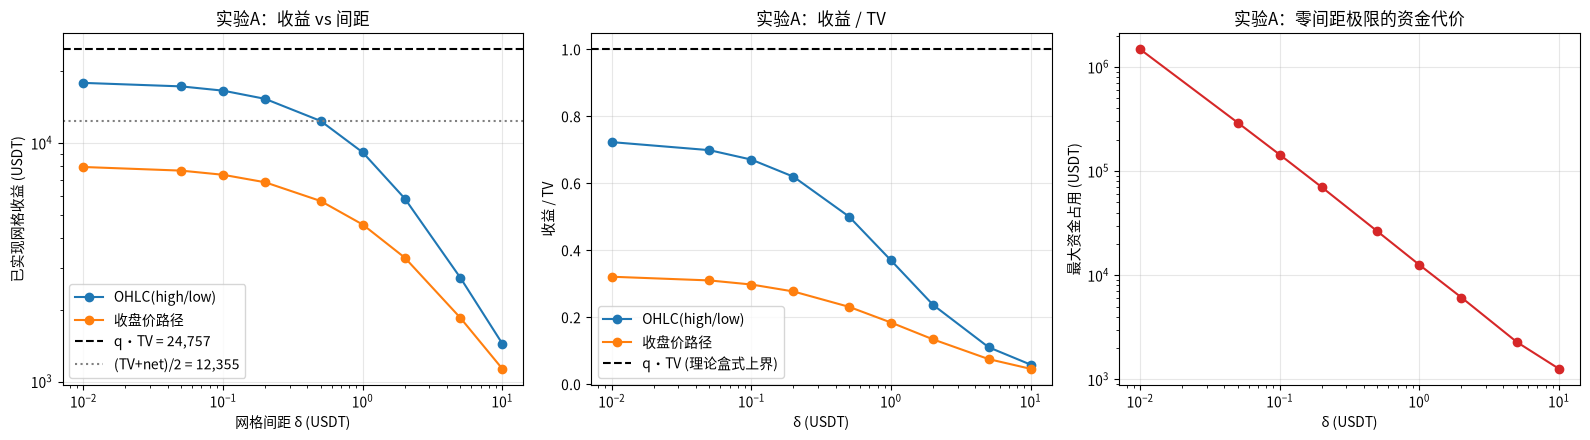

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for tag, sub in dfA.groupby("path"):
    s = sub.sort_values("spacing")
    axes[0].plot(s["spacing"], s["realized_profit"], "o-", label=tag)
axes[0].axhline(TV, color="k", ls="--", label=f"q·TV = {TV:,.0f}")
axes[0].axhline((TV + NET) / 2, color="gray", ls=":", label=f"(TV+net)/2 = {(TV + NET) / 2:,.0f}")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("网格间距 δ (USDT)")
axes[0].set_ylabel("已实现网格收益 (USDT)")
axes[0].set_title("实验A：收益 vs 间距")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for tag, sub in dfA.groupby("path"):
    s = sub.sort_values("spacing")
    axes[1].plot(s["spacing"], s["profit_over_tv"], "o-", label=tag)
axes[1].axhline(1.0, color="k", ls="--", label="q·TV (理论盒式上界)")
axes[1].set_xscale("log")
axes[1].set_xlabel("δ (USDT)")
axes[1].set_ylabel("收益 / TV")
axes[1].set_title("实验A：收益 / TV")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

s = dfA[dfA.path == "OHLC(high/low)"].sort_values("spacing")
axes[2].plot(s["spacing"], s["max_cash_deployed"], "o-", color="C3")
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_xlabel("δ (USDT)")
axes[2].set_ylabel("最大资金占用 (USDT)")
axes[2].set_title("实验A：零间距极限的资金代价")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 实验 A 结论

- 纯多现金网格的收益随 $\delta$ 减小而单调上升并收敛到有限值，但**低于**盒式上界 $q\cdot TV$。原因是纯多网格只在上涨穿越时兑现利润，而 $q\cdot TV$ 假设买卖两侧都能无限成交，需要无限库存或对称网格。
- 采用真实 OHLC 时收益高于收盘价路径，因为高低价让同一根 bar 内也产生可收割的往返；收盘价路径与 $TV$ 定义一致，数值更低。
- 图三显示：收益逼近上界的代价是所需资金随 $\delta\to0$ 以约 $1/\delta$ 增长，印证"固定 $q$ 需无限资金"。

## 实验 A2：对称多空网格

实验 A 的纯多网格只在上涨穿越时兑现。改为对称挂单并允许做空后，下穿可以平空、上穿可以平多，**上下两腿都能兑现**。但一次完整往返仍需两次穿越，因此可实现上界更接近 $q\cdot(TV+\text{net})/2$，而非盒式的 $q\cdot TV$——后者把每次穿越都记为一次 $\delta$，实际上重复计数了一倍。

多空网格用 FIFO 配对结转已实现利润：成交时先平反向手数，余额开新仓；未平仓部分的方向性盈亏由总净值变动体现。

In [5]:
def run_A2(data, tag, fill_at_level=True):
    rows = []
    for d in SPACINGS:
        m = gub.run_experiment(
            data, lower=LOW, upper=HIGH, spacing=d, mode="fixed_q",
            initial_cash=CAP_A[d], q_unit=1.0, fill_at_level=fill_at_level, allow_short=True,
        )["metrics"]
        m = dict(m)
        m["path"] = tag
        m["profit_over_tv"] = m["realized_profit"] / TV
        m["dnav"] = m["final_nav"] - m["initial_cash"]
        rows.append(m)
    return pd.DataFrame(rows)


dfA2 = pd.concat([run_A2(close_path, "收盘价路径"), run_A2(df, "OHLC(high/low)")], ignore_index=True)
dfA2[["path", "spacing", "n_levels", "buys", "sells", "realized_profit",
      "profit_over_tv", "dnav", "peak_long", "peak_short", "final_position"]]

,path,spacing,n_levels,buys,sells,realized_profit,profit_over_tv,dnav,peak_long,peak_short,final_position
0,收盘价路径,10.00,29,215,210,2000.00,0.080784,1982.5715,17.0,12.0,5.0
1,收盘价路径,5.00,57,688,678,3235.00,0.130669,3180.1430,33.0,24.0,10.0
2,收盘价路径,2.00,141,2870,2846,5138.00,0.207535,5104.3432,83.0,58.0,24.0
3,收盘价路径,1.00,282,7687,7639,6454.00,0.260691,6487.6864,165.0,116.0,48.0
4,收盘价路径,0.50,562,18779,18683,6950.00,0.280726,7062.8728,329.0,233.0,96.0
5,收盘价路径,0.20,1404,54571,54332,5000.40,0.201977,5157.7177,822.0,581.0,239.0
6,收盘价路径,0.10,2807,115886,115409,-215.60,-0.008709,147.4211,1643.0,1163.0,477.0
7,收盘价路径,0.05,5613,239490,238536,-11679.30,-0.471753,-10836.3078,3285.0,2327.0,954.0
8,收盘价路径,0.01,28059,1231288,1226519,-106045.17,-4.283398,-101454.9533,16421.0,11638.0,4769.0
9,OHLC(high/low),10.00,29,279,274,2630.00,0.106231,2622.5715,17.0,12.0,5.0


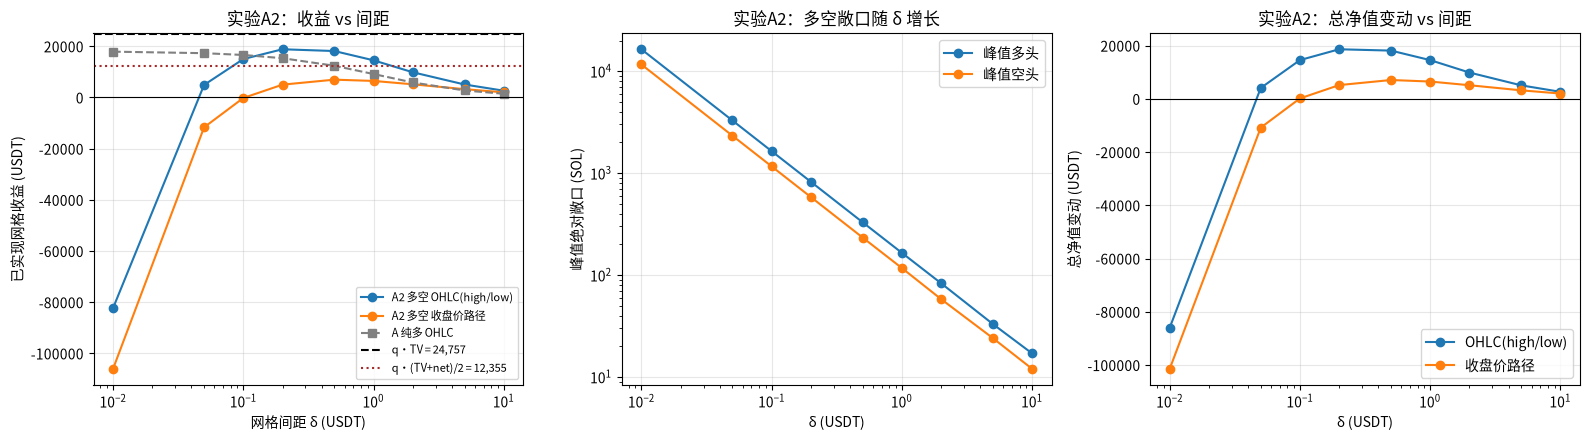

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for tag, sub in dfA2.groupby("path"):
    s = sub.sort_values("spacing")
    axes[0].plot(s["spacing"], s["realized_profit"], "o-", label=f"A2 多空 {tag}")
so = dfA[dfA.path == "OHLC(high/low)"].sort_values("spacing")
axes[0].plot(so["spacing"], so["realized_profit"], "s--", color="gray", label="A 纯多 OHLC")
axes[0].axhline(TV, color="k", ls="--", label=f"q·TV = {TV:,.0f}")
axes[0].axhline((TV + NET) / 2, color="brown", ls=":", label=f"q·(TV+net)/2 = {(TV + NET) / 2:,.0f}")
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xscale("log")
axes[0].set_xlabel("网格间距 δ (USDT)")
axes[0].set_ylabel("已实现网格收益 (USDT)")
axes[0].set_title("实验A2：收益 vs 间距")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

s = dfA2[dfA2.path == "OHLC(high/low)"].sort_values("spacing")
axes[1].plot(s["spacing"], s["peak_long"], "o-", color="C0", label="峰值多头")
axes[1].plot(s["spacing"], s["peak_short"], "o-", color="C1", label="峰值空头")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("δ (USDT)")
axes[1].set_ylabel("峰值绝对敞口 (SOL)")
axes[1].set_title("实验A2：多空敞口随 δ 增长")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

for tag, sub in dfA2.groupby("path"):
    s = sub.sort_values("spacing")
    axes[2].plot(s["spacing"], s["dnav"], "o-", label=tag)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_xscale("log")
axes[2].set_xlabel("δ (USDT)")
axes[2].set_ylabel("总净值变动 (USDT)")
axes[2].set_title("实验A2：总净值变动 vs 间距")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 实验 A2 结论

- 多空网格在中等间距（约 $\delta=0.2\sim0.5$）收益高于纯多，说明收割上下两腿确实有效。
- 但随 $\delta\to0$，峰值多空敞口以约 $1/\delta$ 增长，网格在单边行情里不断累积方向性库存，FIFO 已实现利润与总净值双双转负、加速恶化。
- 因此对称多空并不会让收益趋于 $q\cdot TV$；盒式上界高估了约一倍，且忽略了做空敞口的方向性风险。真正可控的上界是 $q\cdot(TV+\text{net})/2$ 量级，且需要合理的敞口约束。

In [7]:
M = 100_000


def run_B(data, tag, fill_at_level=True):
    rows = []
    for d in SPACINGS:
        m = gub.run_experiment(
            data, lower=LOW, upper=HIGH, spacing=d, mode="fixed_capital",
            initial_cash=M, fill_at_level=fill_at_level,
        )["metrics"]
        m = dict(m)
        m["path"] = tag
        m["profit_over_tv"] = m["realized_profit"] / TV
        rows.append(m)
    return pd.DataFrame(rows)


dfB = pd.concat([run_B(close_path, "收盘价路径"), run_B(df, "OHLC(high/low)")], ignore_index=True)
dfB[["path", "spacing", "n_levels", "buys", "sells", "realized_profit",
     "profit_over_tv", "max_cash_deployed", "capital_exhausted"]]

,path,spacing,n_levels,buys,sells,realized_profit,profit_over_tv,max_cash_deployed,capital_exhausted
0,收盘价路径,10.00,29,118,113,41770.042952,1.687184,51394.259552,False
1,收盘价路径,5.00,57,380,370,33667.841834,1.359918,48927.663730,False
2,收盘价路径,2.00,141,1678,1654,23836.545655,0.962811,51552.802967,False
3,收盘价路径,1.00,282,4601,4553,16904.412899,0.682806,52994.273012,False
4,收盘价路径,0.50,562,11527,11431,10989.284092,0.443881,54841.032974,False
5,收盘价路径,0.20,1404,34493,34254,5575.748767,0.225217,56618.843060,False
6,收盘价路径,0.10,2807,74129,73652,3125.201807,0.126234,57446.928717,False
7,收盘价路径,0.05,5613,154308,153354,1673.473833,0.067595,57943.206637,False
8,收盘价路径,0.01,28059,798813,794044,357.355667,0.014434,58398.872439,False
9,OHLC(high/low),10.00,29,149,144,52227.195238,2.109571,46626.748034,False


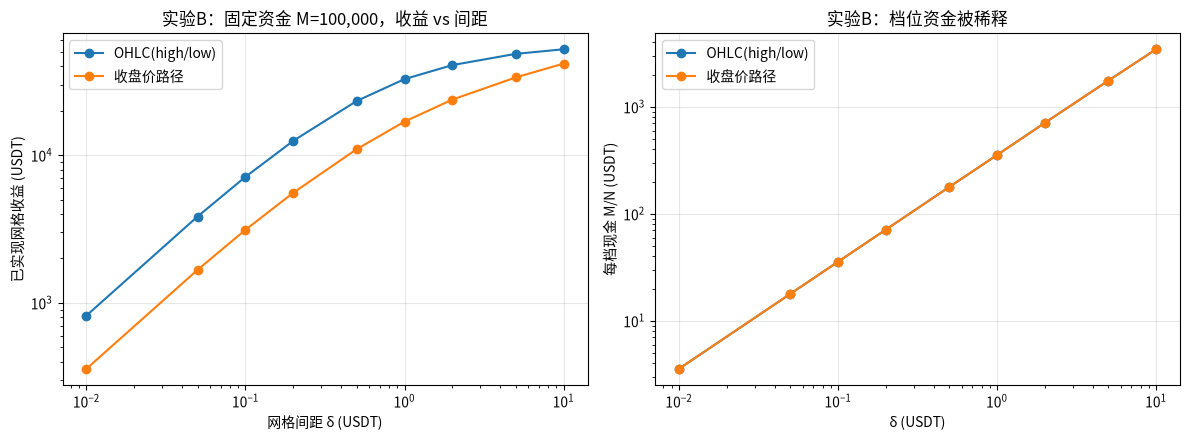

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for tag, sub in dfB.groupby("path"):
    s = sub.sort_values("spacing")
    axes[0].plot(s["spacing"], s["realized_profit"], "o-", label=tag)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("网格间距 δ (USDT)")
axes[0].set_ylabel("已实现网格收益 (USDT)")
axes[0].set_title(f"实验B：固定资金 M={M:,}，收益 vs 间距")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for tag, sub in dfB.groupby("path"):
    s = sub.sort_values("spacing")
    axes[1].plot(s["spacing"], M / s["n_levels"], "o-", label=tag)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("δ (USDT)")
axes[1].set_ylabel("每档现金 M/N (USDT)")
axes[1].set_title("实验B：档位资金被稀释")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 实验 B 结论

固定总资金 $M$ 时，网格数 $N=(U-L)/\delta$ 随 $\delta\to0$ 增长，每档现金 $M/N$ 与成交量被无限稀释，单次往返利润 $\delta\cdot q_i = \delta\cdot(M/N)/p_i \propto \delta^2$ 下降得比穿越次数 $\propto 1/\delta$ 的增长更快，因此总收益随 $\delta\to0$ **趋于零**。这与实验 A 形成鲜明对照：零间距不是免费的午餐，关键在于资金是否随间距同步扩张。

In [9]:
out = pd.concat([dfA, dfA2, dfB], ignore_index=True)
cols = ["path", "mode", "allow_short", "spacing", "n_levels", "buys", "sells",
        "realized_profit", "profit_over_tv", "max_cash_deployed", "capital_exhausted",
        "peak_long", "peak_short", "final_position", "final_nav", "initial_cash"]
out = out[cols]
OUT_CSV = ROOT / "data" / "grid_upper_bound_results.csv"
out.to_csv(OUT_CSV, index=False)
print("saved:", OUT_CSV)
out.tail(15)

saved: /home/nullwinters/Projects/CryptoGrid/data/grid_upper_bound_results.csv


,path,mode,allow_short,spacing,n_levels,buys,sells,realized_profit,profit_over_tv,max_cash_deployed,capital_exhausted,peak_long,peak_short,final_position,final_nav,initial_cash
39,收盘价路径,fixed_capital,False,1.00,282,4601,4553,16904.412899,0.682806,52994.273012,False,1098.964315,1.203482e-13,115.408848,114286.160566,100000.0
40,收盘价路径,fixed_capital,False,0.50,562,11527,11431,10989.284092,0.443881,54841.032974,False,1091.298647,6.417089e-14,116.018302,108386.517624,100000.0
41,收盘价路径,fixed_capital,False,0.20,1404,34493,34254,5575.748767,0.225217,56618.843060,False,1085.641161,5.527800e-13,115.490031,102966.112636,100000.0
42,收盘价路径,fixed_capital,False,0.10,2807,74129,73652,3125.201807,0.126234,57446.928717,False,1083.761909,4.685141e-14,115.285246,100519.569326,100000.0
43,收盘价路径,fixed_capital,False,0.05,5613,154308,153354,1673.473833,0.067595,57943.206637,False,1082.825017,6.040862e-13,115.325520,99069.840001,100000.0
44,收盘价路径,fixed_capital,False,0.01,28059,798813,794044,357.355667,0.014434,58398.872439,False,1082.153945,1.238593e-15,115.337416,97755.136082,100000.0
45,OHLC(high/low),fixed_capital,False,10.00,29,149,144,52227.195238,2.109571,46626.748034,False,1294.330395,1.776357e-13,117.345555,149630.541236,100000.0
46,OHLC(high/low),fixed_capital,False,5.00,57,554,545,48618.671327,1.963815,42651.286463,False,1177.903239,3.907985e-14,107.298168,146220.008985,100000.0
47,OHLC(high/low),fixed_capital,False,2.00,141,2952,2928,40812.280600,1.648498,45350.308198,False,1122.671544,5.684342e-13,115.014142,138144.768942,100000.0
48,OHLC(high/low),fixed_capital,False,1.00,282,9192,9144,32795.546304,1.324684,46855.637097,False,1098.964315,0.000000e+00,115.408848,130177.293972,100000.0


## 总结与局限

1. 盒式上界 $q\cdot TV$ 把每次穿越都记为一次 $\delta$，但一次完整往返需要两次穿越，因此高估了约一倍；更贴近可实现情形的是 $q\cdot(TV+\text{net})/2$。纯多网格实测低于该值，对称多空在中等间距可接近但在细间距因方向性敞口失控而恶化。
2. 采用收盘价路径时 $TV$ 与网格所依赖的路径一致；采用 OHLC 高低价会额外收割盘中往返，收益更高，但此时参考的 $TV$ 应相应改按盘中路径计算。
3. 固定资金下 $\delta\to0$ 收益趋于零，是实验 B 的核心结论。
4. 未含手续费、滑点、最小报价单位与真实保证金约束；引擎仅做单次触发，未模拟 bar 内路径穿越，也未对多空敞口设限。